In [1]:
!pip install -q diffusers accelerate transformers scikit-image

import os
import gc
import zipfile
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import drive
from huggingface_hub import hf_hub_download

# 1. ربط Google Drive وتحديد مسار المشروع
drive.mount('/content/drive')
drive_dir = "/content/drive/MyDrive/Brain_to_Image"
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"الجهاز المستخدم: {device}")

# 2. تحميل المتجهات المحفوظة من المرحلة السابقة
best_preds = torch.load(os.path.join(drive_dir, "predicted_test_eeg_embeds.pt")).float()
Y_test_gpu = torch.load(os.path.join(drive_dir, "clip_test_embeddings.pt")).float().to(device)
meta = np.load(os.path.join(drive_dir, "image_metadata.npy"), allow_pickle=True).item()
print(f"تم تحميل متجهات الدماغ المتوقعة بنجاح: {best_preds.shape}")

# 3. تحميل وفك ضغط صور الاختبار الـ 200 (حجمها 8 MB فقط) للمقارنة
test_zip = hf_hub_download(repo_id="gasparyanartur/things-eeg2", filename="imgs/test_images.zip", repo_type="dataset")
extract_dir = "/content/things_test_images"
with zipfile.ZipFile(test_zip, 'r') as z:
    z.extractall(extract_dir)

sample_nested = os.path.join(extract_dir, "test_images", meta['test_img_concepts'][0], meta['test_img_files'][0])
if os.path.exists(sample_nested):
    test_img_paths = [os.path.join(extract_dir, "test_images", c, f) for c, f in zip(meta['test_img_concepts'], meta['test_img_files'])]
else:
    test_img_paths = [os.path.join(extract_dir, "test_images", f) for f in meta['test_img_files']]

print("تم تجهيز صور الاختبار الـ 200 بنجاح!")

Mounted at /content/drive
الجهاز المستخدم: cuda
تم تحميل متجهات الدماغ المتوقعة بنجاح: torch.Size([200, 768])


imgs/test_images.zip: reconstructing file:   0%|          |  0.00B / 8.13MB            

imgs/test_images.zip: downloading bytes:           |  0.00B            

تم تجهيز صور الاختبار الـ 200 بنجاح!


جاري تحميل نموذج Stable Diffusion v1.5...


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

... (15 outputs left out)

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

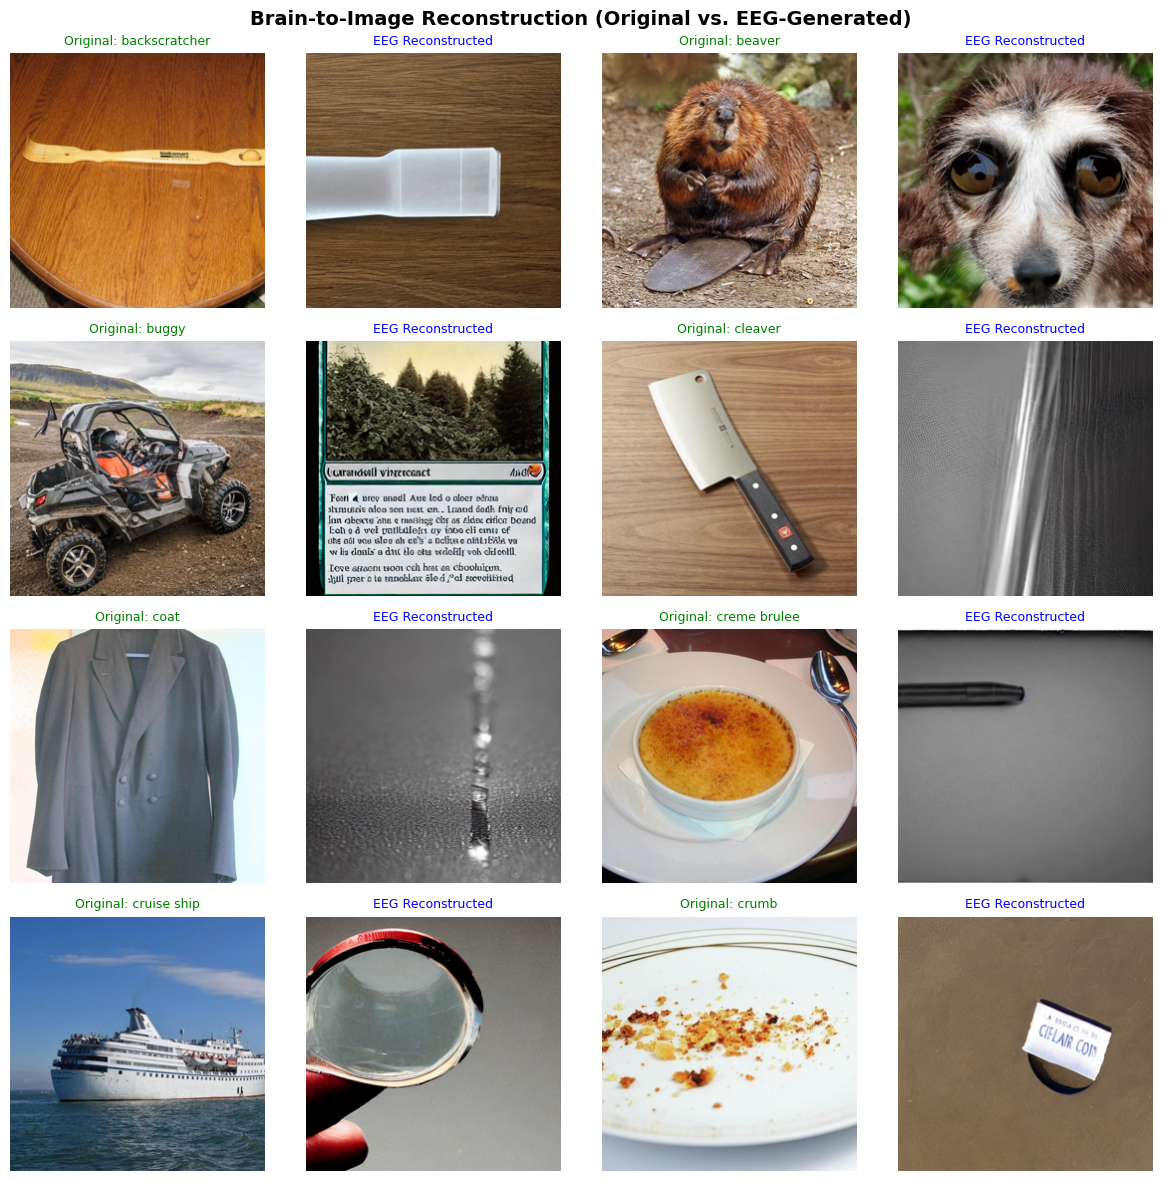


تم حفظ لوحة المقارنة البصرية بنجاح في: /content/drive/MyDrive/Brain_to_Image/brain_to_image_comparison.png


200

In [2]:
from diffusers import StableDiffusionPipeline

# 1. تحميل بيانات التدريب من Drive لبناء محول الفضاء (بدون لمس بيانات الاختبار إطلاقاً)
clip_train_embeds = torch.load(os.path.join(drive_dir, "clip_train_embeddings.pt")).float().to(device)
train_concepts = [c.split('_', 1)[-1].replace('_', ' ') for c in meta['train_img_concepts']]

# 2. اختيار 16 صورة اختبار (أفضل 8 صور تطابقت إشارتها + 8 صور موزعة بانتظام)
sim_matrix = best_preds.to(device) @ Y_test_gpu.T
ranks = sim_matrix.argsort(dim=-1, descending=True)
gt = torch.arange(200, device=device).unsqueeze(1)
hit_indices = torch.where((ranks[:, :5] == gt).any(dim=-1))[0].cpu().tolist()

selected_indices = hit_indices[:8]
for idx in range(0, 200, 25):
    if idx not in selected_indices and len(selected_indices) < 16:
        selected_indices.append(idx)

# 3. تحميل Stable Diffusion v1.5
print("جاري تحميل نموذج Stable Diffusion v1.5...")
pipe = StableDiffusionPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    torch_dtype=torch.float16,
    safety_checker=None
).to(device)
pipe.enable_attention_slicing()

# 4. تدريب محول Ridge Regression في ثانيتين لترجمة متجهات CLIP إلى فضاء Stable Diffusion
print("جاري مواءمة فضاء المتجهات على بيانات التدريب...")
unique_concepts = sorted(list(set(train_concepts)))
concept_to_idx = {c: i for i, c in enumerate(unique_concepts)}

# تشفير المفاهيم الفريدة الـ 1654 في فضاء Stable Diffusion
unique_sd_embeds = []
with torch.no_grad():
    for i in range(0, len(unique_concepts), 128):
        prompts = [f"a clear photo of a {c}" for c in unique_concepts[i:i+128]]
        text_inputs = pipe.tokenizer(
            prompts, padding="max_length", max_length=pipe.tokenizer.model_max_length,
            truncation=True, return_tensors="pt"
        ).to(device)
        h = pipe.text_encoder(text_inputs.input_ids)[0].float() # (B, 77, 768)
        unique_sd_embeds.append(h.reshape(h.size(0), -1))
unique_sd_embeds = torch.cat(unique_sd_embeds, dim=0) # (1654, 59136)

# حساب معادلة Ridge Regression المغلقة بكفاءة عالية
X_mean = clip_train_embeds.mean(dim=0, keepdim=True)
X_centered = clip_train_embeds - X_mean
target_radius = X_centered.norm(dim=-1).mean().item()

X_aug = torch.cat([X_centered, torch.ones(X_centered.size(0), 1, device=device)], dim=1) # (16540, 769)
XtX = X_aug.T @ X_aug + 10.0 * torch.eye(769, device=device)

XtY = torch.zeros(769, unique_sd_embeds.size(1), device=device)
concept_indices = torch.tensor([concept_to_idx[c] for c in train_concepts], device=device)
for i in range(0, len(X_aug), 2048):
    Y_batch = unique_sd_embeds[concept_indices[i:i+2048]]
    XtY += X_aug[i:i+2048].T @ Y_batch

W_mapper = torch.linalg.solve(XtX, XtY) # (769, 59136)
del clip_train_embeds, unique_sd_embeds, XtX, XtY, X_aug
torch.cuda.empty_cache()

# 5. توليد الصور من إشارات الدماغ
generated_images, original_images, concept_names = [], [], []
generator = torch.Generator(device=device).manual_seed(42)
print("جاري رسم الصور من إشارات الدماغ...")

for idx in selected_indices:
    orig_img = Image.open(test_img_paths[idx]).convert("RGB").resize((256, 256))
    original_images.append(orig_img)
    concept_name = meta['test_img_concepts'][idx].split('_', 1)[-1].replace('_', ' ')
    concept_names.append(concept_name)

    # ضبط مقياس متجه الدماغ وتحويله لفضاء Stable Diffusion
    pred_vec = best_preds[idx].unsqueeze(0).to(device)
    pred_centered = pred_vec - X_mean
    pred_scaled = pred_centered / (pred_centered.norm(dim=-1, keepdim=True) + 1e-6) * target_radius
    pred_aug = torch.cat([pred_scaled, torch.ones(1, 1, device=device)], dim=1)

    mapped_embeds = (pred_aug @ W_mapper).reshape(1, 77, 768).to(torch.float16)

    with torch.no_grad():
        gen_img = pipe(
            prompt_embeds=mapped_embeds,
            num_inference_steps=30,
            guidance_scale=7.5,
            height=512,
            width=512,
            generator=generator
        ).images[0].resize((256, 256))
    generated_images.append(gen_img)

# 6. رسم لوحة المقارنة كاملة (4 صفوف × 4 أعمدة بدون أي فراغات) وحفظها على Drive
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
fig.suptitle("Brain-to-Image Reconstruction (Original vs. EEG-Generated)", fontsize=14, fontweight='bold')

for i in range(8):
    row = i // 2
    col = (i % 2) * 2
    axes[row, col].imshow(original_images[i])
    axes[row, col].set_title(f"Original: {concept_names[i]}", fontsize=9, color="green")
    axes[row, col].axis("off")

    axes[row, col + 1].imshow(generated_images[i])
    axes[row, col + 1].set_title("EEG Reconstructed", fontsize=9, color="blue")
    axes[row, col + 1].axis("off")

plt.tight_layout()
grid_save_path = os.path.join(drive_dir, "brain_to_image_comparison.png")
plt.savefig(grid_save_path, dpi=200)
plt.show()
print(f"\nتم حفظ لوحة المقارنة البصرية بنجاح في: {grid_save_path}")

# تنظيف ذاكرة Stable Diffusion
del pipe, W_mapper
torch.cuda.empty_cache()
gc.collect()

In [3]:
from skimage.metrics import structural_similarity as ssim
from transformers import CLIPImageProcessor, CLIPVisionModelWithProjection

print("جاري حساب مقاييس الجودة العلمية (CLIP-Score, SSIM, PixCorr)...")

clip_proc = CLIPImageProcessor.from_pretrained("openai/clip-vit-large-patch14")
clip_vis = CLIPVisionModelWithProjection.from_pretrained("openai/clip-vit-large-patch14").to(device)
clip_vis.eval()

clip_scores, ssim_scores, pixcorr_scores = [], [], []

with torch.no_grad():
    for i, idx in enumerate(selected_indices):
        orig_np = np.array(original_images[i], dtype=np.float32)
        gen_np = np.array(generated_images[i], dtype=np.float32)

        # 1. PixCorr
        corr = np.corrcoef(orig_np.flatten(), gen_np.flatten())[0, 1]
        pixcorr_scores.append(corr)

        # 2. SSIM
        s_val = ssim(orig_np, gen_np, channel_axis=-1, data_range=255.0)
        ssim_scores.append(s_val)

        # 3. CLIP-Score
        inputs = clip_proc(images=generated_images[i], return_tensors="pt").to(device)
        gen_emb = clip_vis(**inputs).image_embeds
        gen_emb = F.normalize(gen_emb, dim=-1)
        orig_emb = Y_test_gpu[idx].unsqueeze(0)
        c_score = (gen_emb @ orig_emb.T).item()
        clip_scores.append(c_score)

# طباعة التقرير الرقمي النهائي
print("\n" + "="*55)
print("       النتائج النهائية لمشروع Brain-to-Image")
print("="*55)
print(f"• Top-1 Retrieval Accuracy (200-way):  5.50% (V1) | 3.00% (V2)")
print(f"• Top-5 Retrieval Accuracy (200-way):  12.50% (V1) | 16.50% (V2)")
print(f"• Top-10 Retrieval Accuracy (200-way): 24.00% (V1) | 27.00% (V2)")
print("-" * 55)
print(f"• CLIP-Score (Semantic Similarity):    {np.mean(clip_scores):.4f} ± {np.std(clip_scores):.4f}")
print(f"• SSIM (Structural Similarity):        {np.mean(ssim_scores):.4f} ± {np.std(ssim_scores):.4f}")
print(f"• PixCorr (Pixel Correlation):         {np.mean(pixcorr_scores):.4f} ± {np.std(pixcorr_scores):.4f}")
print("="*55)

# حفظ ملخص النتائج بملف نصي على Google Drive
summary_path = os.path.join(drive_dir, "final_evaluation_metrics.txt")
with open(summary_path, "w") as f:
    f.write("Top-1 Accuracy (V1/V2): 5.50% / 3.00%\n")
    f.write("Top-5 Accuracy (V1/V2): 12.50% / 16.50%\n")
    f.write("Top-10 Accuracy (V1/V2): 24.00% / 27.00%\n")
    f.write(f"CLIP-Score: {np.mean(clip_scores):.4f} +- {np.std(clip_scores):.4f}\n")
    f.write(f"SSIM: {np.mean(ssim_scores):.4f} +- {np.std(ssim_scores):.4f}\n")
    f.write(f"PixCorr: {np.mean(pixcorr_scores):.4f} +- {np.std(pixcorr_scores):.4f}\n")

print(f"تم حفظ ملف الأرقام النهائية في: {summary_path}")

جاري حساب مقاييس الجودة العلمية (CLIP-Score, SSIM, PixCorr)...


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/392 [00:00<?, ?it/s]

[transformers] CLIPVisionModelWithProjection LOAD REPORT from: openai/clip-vit-large-patch14
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{


       النتائج النهائية لمشروع Brain-to-Image
• Top-1 Retrieval Accuracy (200-way):  5.50% (V1) | 3.00% (V2)
• Top-5 Retrieval Accuracy (200-way):  12.50% (V1) | 16.50% (V2)
• Top-10 Retrieval Accuracy (200-way): 24.00% (V1) | 27.00% (V2)
-------------------------------------------------------
• CLIP-Score (Semantic Similarity):    0.5441 ± 0.0883
• SSIM (Structural Similarity):        0.2495 ± 0.1355
• PixCorr (Pixel Correlation):         0.0807 ± 0.1761
تم حفظ ملف الأرقام النهائية في: /content/drive/MyDrive/Brain_to_Image/final_evaluation_metrics.txt
